In [2]:
import torch
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd

In [3]:
test_results = pd.read_csv('config.csv', dtype=str)
# to dataframe
test_results = pd.DataFrame(test_results)
# Strip any leading or trailing spaces from the column names
test_results.columns = test_results.columns.str.strip()
test_results = test_results.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
file_list = []
for i in range(len(test_results)):
    seeds = test_results.iloc[i]['seed'].split(' ')
    dataset = test_results.iloc[i]['dataset']
    usage = test_results.iloc[i]['usage']
    model = test_results.iloc[i]['model']
    lr = test_results.iloc[i]['lr']
    snr = test_results.iloc[i]['snr']
    snvr = test_results.iloc[i]['snvr']
    weight_decay = test_results.iloc[i]['weight_decay']
    
    valid_top1_acc_list = []
    valid_top5_acc_list = []
    test_top1_acc_list = []
    test_top5_acc_list = []

    ckpt_path = f'./ckpt/{dataset}_{usage}_{model}_{lr}_{snr}_{snvr}_{weight_decay}.pth'
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path)
        file_list.append(ckpt_path.split('/')[-1])
    
        for seed in ckpt.keys():
            valid_top1_acc_list.append(ckpt[seed]['best_epoch']['valid_top1_acc']*100)
            valid_top5_acc_list.append(ckpt[seed]['best_epoch']['valid_top5_acc']*100)
            test_top1_acc_list.append(ckpt[seed]['best_epoch']['test_top1_acc']*100)
            test_top5_acc_list.append(ckpt[seed]['best_epoch']['test_top5_acc']*100)
    
    test_results.at[i, 'seed'] = f'{len(valid_top1_acc_list)}/{len(seeds)}'
    if len(valid_top1_acc_list) == 0: continue
    test_results.at[i, 'valid_acc@1'] = f'{np.mean(valid_top1_acc_list):.2f} ± {np.std(valid_top1_acc_list):.2f}'
    test_results.at[i, 'valid_acc@5'] = f'{np.mean(valid_top5_acc_list):.2f} ± {np.std(valid_top5_acc_list):.2f}'
    test_results.at[i, 'test_acc@1'] = f'{np.mean(test_top1_acc_list):.2f} ± {np.std(test_top1_acc_list):.2f}'
    test_results.at[i, 'test_acc@5'] = f'{np.mean(test_top5_acc_list):.2f} ± {np.std(test_top5_acc_list):.2f}'

test_results = test_results.drop(columns=['epochs','warm_up','batch_size', 'optim'])
print(test_results.to_string())

   seed       dataset usage             model    lr   snr  snvr weight_decay   valid_acc@1   valid_acc@5    test_acc@1    test_acc@5
0   0/1      imagenet   0.1         swin_tiny  1e-3   0.0   0.0         0.05           NaN           NaN           NaN           NaN
1   1/1  imagenet-112  0.05     convnext_tiny  4e-3   0.0   0.0         1e-5  16.41 ± 0.00  34.64 ± 0.00  14.71 ± 0.00  32.53 ± 0.00
2   1/1  imagenet-112  0.05     convnext_tiny  4e-3  1e-4   0.0          0.0  16.94 ± 0.00  32.58 ± 0.00  15.73 ± 0.00  31.16 ± 0.00
3   1/1  imagenet-112  0.05     convnext_tiny  4e-3  1e-5   0.0          0.0  20.01 ± 0.00  36.48 ± 0.00  17.94 ± 0.00  34.48 ± 0.00
4   1/1  imagenet-112  0.05     convnext_tiny  4e-3  1e-6   0.0          0.0  20.18 ± 0.00  37.01 ± 0.00  18.21 ± 0.00  35.00 ± 0.00
5   1/1  imagenet-112  0.05     convnext_tiny  4e-3  1e-7   0.0          0.0  18.83 ± 0.00  35.20 ± 0.00  17.15 ± 0.00  33.10 ± 0.00
6   1/1  imagenet-112  0.05     convnext_tiny  4e-3  1e-6   1.0      

In [4]:
for file in os.listdir('./ckpt/'):
    if file in file_list:
        print(file)
    # if file not in file_list:
    #     os.remove(f'./ckpt/{file}')

imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-4_0.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_0.01_0.0_1e-3.pth
imagenet-112_0.05_convnext_tiny_4e-3_0.0_0.0_1e-5.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-6_1e-3_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_0.0_0.0_1e-3.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-5_0.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-4_1.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-4_0.0_1e-3.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-5_0.1_0.0.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-4_0.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_0.0_0.0_1e-5.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-6_0.1_0.0.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-5_0.01_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-5_0.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-7_0.0_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-3_0.0_1e-3.pth
imagenet-112_0.05_convnext_tiny_4e-3_1e-6_0.01_0.0.pth
imagenet-112_0.05_swin-v2_tiny-0.5_1e-4_1e-3_0.0_

Using matplotlib backend: module://matplotlib_inline.backend_inline


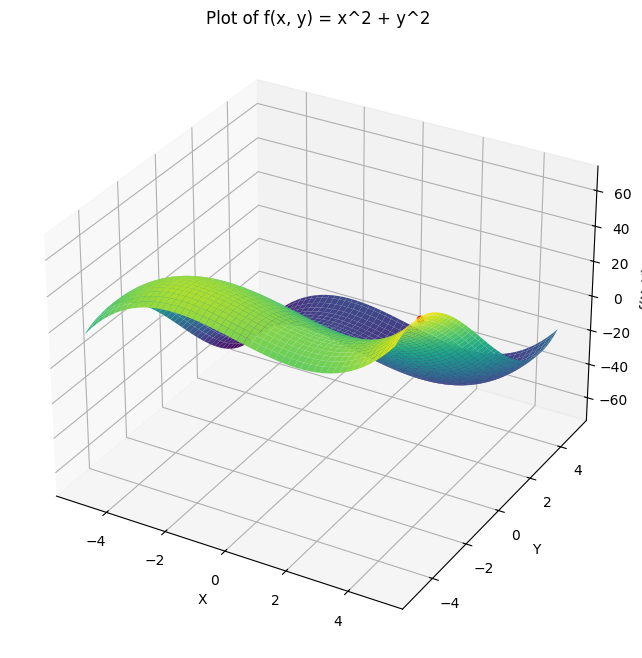

In [5]:
%matplotlib
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the function
def f(x, y):
  return 1/3*x**3 - 4*x + 1/3*y**3 - 16*y

# Create a grid of x and y values
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)

# Calculate the z values
Z = f(X, Y)

# Create the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis')

# Set labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('f(X, Y)')
ax.set_title('Plot of f(x, y) = x^2 + y^2')

ax.scatter(2, 2, c='r')

# Show the plot
plt.ioff()
plt.show()